# 04 — Small CNN trained from scratch: RGB vs 13 spectral bands

This notebook trains a compact convolutional neural network from scratch on RGB (3 channels) and on all 13 bands, using the **same fixed split, training-only normalisation and augmentation** from notebook 02. The only architecture change is the number of input channels.

**Implementation:** Model, training, and evaluation functions are implemented inside this notebook so it can be reviewed and executed independently. Once the team agrees on the design, reusable functions can be moved into `src/piece_of_crop/cnn.py` and `src/piece_of_crop/train.py` without changing the experiment. These files are not overwritten here.

**Inputs:** `results/split.csv`, `results/band_stats.csv` and the shared EuroSAT cache (`data/eurosat_cache.npy`) or raw `data/EuroSAT_MS` files.

**Outputs:** `results/cnn_results.csv`, `results/cnn_history.csv`, test prediction CSVs `results/predictions/cnn_<input>_seed<n>.csv`, training curves in `results/figures/` and local model weights in `models/` (do not commit weights or data).

**Design:** Conv–BatchNorm–ReLU blocks and pooling, followed by global average pooling and a 10-class head. Train on three seeds, choose each best checkpoint using *validation loss only*, and evaluate the held-out test split afterward. No hyperparameter tuning on test data.


## 1. Shared setup and data from notebook 02

This uses the original `piece_of_crop` package (the public API already used by notebook 02). It adds the repository's `src/` directory to Python's import path so VS Code can find the package without a separate editable installation. Run the notebook **inside the cloned repository**, not from Downloads.


In [1]:
from pathlib import Path
import sys
import random

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, f1_score

# Works when the Jupyter working directory is the project root or notebooks/.
def find_project_root():
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / 'src' / 'piece_of_crop' / 'data.py').is_file():
            return candidate
    raise FileNotFoundError('Open the piece_of_crop repository in VS Code; src/piece_of_crop/data.py not found.')

project_root = find_project_root()
src_dir = str(project_root / 'src')
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from piece_of_crop import get_cache, make_loaders, read_split, CLASS_NAMES

SEEDS = (0, 1, 2)
BATCH_SIZE = 64
MAX_EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

results_dir = project_root / 'results'
figures_dir = results_dir / 'figures'
predictions_dir = results_dir / 'predictions'
models_dir = project_root / 'models'
data_dir = project_root / 'data' / 'EuroSAT_MS'
for folder in (results_dir, figures_dir, predictions_dir, models_dir):
    folder.mkdir(parents=True, exist_ok=True)

split = read_split(results_dir / 'split.csv')
band_stats = pd.read_csv(results_dir / 'band_stats.csv')
cache = get_cache(split, data_dir, project_root / 'data' / 'eurosat_cache.npy')
label_ids = np.sort(split['label'].unique()).astype(int)
assert len(label_ids) == 10 and np.array_equal(label_ids, np.arange(10)), 'Expected labels 0..9.'

if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('Repository:', project_root)
print('Device:', device)
print('Patches:', split['split'].value_counts().to_dict())
print('Cache:', cache.shape)


Cache already exists: /Users/faris/Documents/piece_of_crop/data/eurosat_cache.npy
Repository: /Users/faris/Documents/piece_of_crop
Device: mps
Patches: {'train': 19794, 'val': 3584, 'test': 3515, 'buffer': 107}
Cache: (27000, 13, 64, 64)


## 2. Model architecture

A deliberately small CNN keeps the RGB and 13-band comparison interpretable. It uses three Conv–BatchNorm–ReLU–MaxPool blocks (32, 64, 128 channels), global average pooling and a linear classification layer. Inputs stay at the original 64 × 64 resolution; no pretrained weights are used.

In [2]:
from torch import nn

class SmallCNN(nn.Module):
    def __init__(self, in_channels: int, num_classes: int = 10):
        super().__init__()
        blocks = []
        channels = in_channels
        for out_channels in (32, 64, 128):
            blocks.extend([
                nn.Conv2d(channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2),
            ])
            channels = out_channels
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.head(self.features(x))

# Shape check without touching the dataset.
for channels in (3, 13):
    test_model = SmallCNN(channels)
    assert test_model(torch.randn(2, channels, 64, 64)).shape == (2, 10)
print('CNN shape checks passed (3 and 13 input channels).')


CNN shape checks passed (3 and 13 input channels).


## 3. Training and evaluation helpers

Use cross-entropy loss, AdamW and early stopping based on **validation loss**. The test split is only evaluated after selecting the best validation checkpoint. Accuracy, macro-F1 and per-class classification are calculated with the same definitions as notebook 03.

In [3]:
import copy

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0.0
    total_n = 0
    correct = 0
    for images, labels in loader:
        images = images.to(device=device, dtype=torch.float32)
        labels = labels.to(device=device, dtype=torch.long)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        n = len(labels)
        total_loss += loss.item() * n
        total_n += n
        correct += (logits.argmax(dim=1) == labels).sum().item()
    return total_loss / total_n, correct / total_n


@torch.inference_mode()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    total_n = 0
    truths, preds, probabilities = [], [], []
    for images, labels in loader:
        images = images.to(device=device, dtype=torch.float32)
        labels = labels.to(device=device, dtype=torch.long)
        logits = model(images)
        n = len(labels)
        total_loss += loss_fn(logits, labels).item() * n
        total_n += n
        prob = torch.softmax(logits, dim=1).cpu().numpy()
        probabilities.append(prob)
        preds.append(prob.argmax(axis=1))
        truths.append(labels.cpu().numpy())
    y_true = np.concatenate(truths)
    y_pred = np.concatenate(preds)
    proba = np.concatenate(probabilities)
    return {
        'loss': total_loss / total_n,
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, labels=label_ids, average='macro', zero_division=0),
        'y_true': y_true,
        'y_pred': y_pred,
        'proba': proba,
    }


def fit_model(model, loaders, seed, input_type):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.CrossEntropyLoss()
    best_loss = float('inf')
    best_state = None
    stale = 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_accuracy = train_epoch(model, loaders['train'], optimizer, loss_fn)
        val = evaluate(model, loaders['val'], loss_fn)
        history.append({
            'model': 'SmallCNN', 'input': input_type, 'seed': seed,
            'epoch': epoch, 'train_loss': train_loss, 'train_accuracy': train_accuracy,
            'val_loss': val['loss'], 'val_accuracy': val['accuracy'], 'val_macro_f1': val['macro_f1'],
        })
        print(f'{input_type} seed={seed} epoch={epoch:02d} '
              f'train_loss={train_loss:.4f} val_loss={val["loss"]:.4f} '
              f'val_acc={val["accuracy"]:.3f} val_F1={val["macro_f1"]:.3f}')
        if val['loss'] < best_loss - 1e-4:
            best_loss = val['loss']
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= PATIENCE:
                print('Early stopping based on validation loss.')
                break
    model.load_state_dict(best_state)
    return history, loss_fn


## 4. Train RGB and multispectral CNNs

For every seed, recreate the data loaders so the training augmentations follow that seed. Keep identical optimiser settings and epoch limits for RGB and 13-band. Models and predictions are saved separately; the output CSV format matches notebook 03. On an M3 Mac, the notebook will use MPS if PyTorch supports it. The full experiment trains six networks and may be computationally expensive.

In [4]:
history_rows = []
result_rows = []

for input_type, n_channels in (('rgb', 3), ('13band', 13)):
    for seed in SEEDS:
        print(f'\n=== CNN {input_type}, seed {seed} ===')
        set_seed(seed)
        loaders = make_loaders(split, cache, band_stats, input_type,
                               batch_size=BATCH_SIZE, seed=seed)
        sample_images, sample_labels = next(iter(loaders['train']))
        assert sample_images.ndim == 4 and sample_images.shape[1] == n_channels
        assert sample_images.shape[2:] == (64, 64)

        model = SmallCNN(in_channels=n_channels, num_classes=len(CLASS_NAMES)).to(device)
        history, loss_fn = fit_model(model, loaders, seed, input_type)
        history_rows.extend(history)

        # Best checkpoint selected using validation set; test was unseen until now.
        torch.save({'state_dict': model.cpu().state_dict(), 'input': input_type,
                    'seed': seed, 'num_classes': len(CLASS_NAMES)},
                   models_dir / f'cnn_{input_type}_seed{seed}.pt')
        model.to(device)

        for subset in ('val', 'test'):
            outcome = evaluate(model, loaders[subset], loss_fn)
            result_rows.append({
                'model': 'SmallCNN', 'input': input_type, 'seed': seed, 'split': subset,
                'accuracy': outcome['accuracy'], 'macro_f1': outcome['macro_f1'],
                'loss': outcome['loss'], 'n_samples': len(outcome['y_true']),
            })
            if subset == 'test':
                # DataLoader for test is deterministic / unshuffled in notebook 02.
                expected_true = split.loc[split['split'].eq('test'), 'label'].to_numpy(dtype=int)
                if not np.array_equal(outcome['y_true'], expected_true):
                    raise ValueError('Test loader order differs from split.csv. '
                                     'Do not export filenames without verifying alignment.')
                out = pd.DataFrame({
                    'file': split.loc[split['split'].eq('test'), 'file'].to_numpy(),
                    'y_true': outcome['y_true'], 'y_pred': outcome['y_pred'],
                    'confidence': outcome['proba'].max(axis=1),
                })
                for class_id in label_ids:
                    out[f'p_{class_id}'] = outcome['proba'][:, class_id]
                out.to_csv(predictions_dir / f'cnn_{input_type}_seed{seed}.csv', index=False)

# Export only after all six runs finish.
cnn_history = pd.DataFrame(history_rows)
cnn_results = pd.DataFrame(result_rows)
cnn_history.to_csv(results_dir / 'cnn_history.csv', index=False)
cnn_results.to_csv(results_dir / 'cnn_results.csv', index=False)
display(cnn_results)



=== CNN rgb, seed 0 ===
rgb seed=0 epoch=01 train_loss=0.8867 val_loss=0.7818 val_acc=0.720 val_F1=0.672
rgb seed=0 epoch=02 train_loss=0.5709 val_loss=0.5492 val_acc=0.803 val_F1=0.771
rgb seed=0 epoch=03 train_loss=0.4526 val_loss=0.4796 val_acc=0.835 val_F1=0.818
rgb seed=0 epoch=04 train_loss=0.3806 val_loss=0.6553 val_acc=0.758 val_F1=0.735
rgb seed=0 epoch=05 train_loss=0.3528 val_loss=0.5959 val_acc=0.796 val_F1=0.767
rgb seed=0 epoch=06 train_loss=0.3218 val_loss=0.4919 val_acc=0.837 val_F1=0.814
Early stopping based on validation loss.

=== CNN rgb, seed 1 ===
rgb seed=1 epoch=01 train_loss=0.8777 val_loss=0.7863 val_acc=0.717 val_F1=0.687
rgb seed=1 epoch=02 train_loss=0.5713 val_loss=0.7134 val_acc=0.746 val_F1=0.711
rgb seed=1 epoch=03 train_loss=0.4790 val_loss=0.6560 val_acc=0.767 val_F1=0.742
rgb seed=1 epoch=04 train_loss=0.4155 val_loss=0.8861 val_acc=0.731 val_F1=0.684
rgb seed=1 epoch=05 train_loss=0.3771 val_loss=0.4717 val_acc=0.839 val_F1=0.821
rgb seed=1 epoch=0

,model,input,seed,split,accuracy,macro_f1,loss,n_samples
0,SmallCNN,rgb,0,val,0.835379,0.817983,0.479636,3584
1,SmallCNN,rgb,0,test,0.863442,0.841005,0.396754,3515
2,SmallCNN,rgb,1,val,0.861607,0.845315,0.408552,3584
3,SmallCNN,rgb,1,test,0.880797,0.859557,0.353493,3515
4,SmallCNN,rgb,2,val,0.876395,0.860679,0.368089,3584
5,SmallCNN,rgb,2,test,0.883357,0.870736,0.337681,3515
6,SmallCNN,13band,0,val,0.929967,0.923508,0.204823,3584
7,SmallCNN,13band,0,test,0.949075,0.945793,0.164554,3515
8,SmallCNN,13band,1,val,0.888114,0.878737,0.356432,3584
9,SmallCNN,13band,1,test,0.926031,0.918620,0.225287,3515


## 5. Training curves and model comparison

Inspect training vs validation loss, the mean and standard deviation of accuracy/macro-F1 over seeds, and per-class classification reports. The plot and tables are based on executed model results; they are not pre-filled estimates.

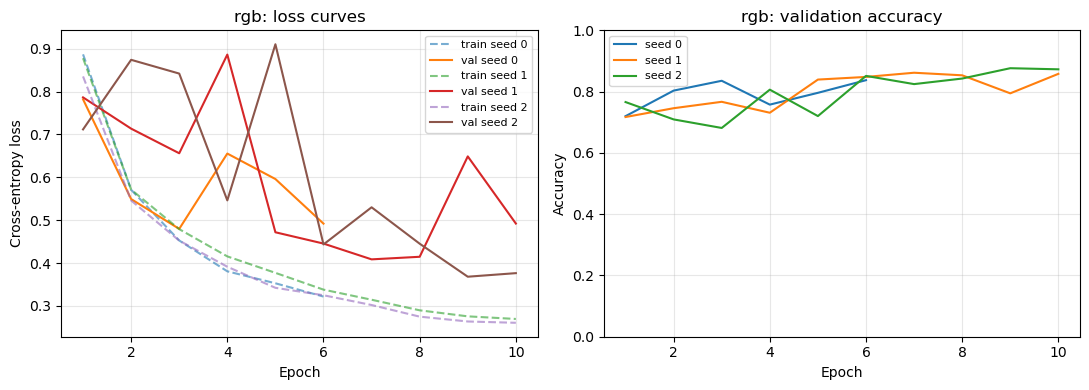

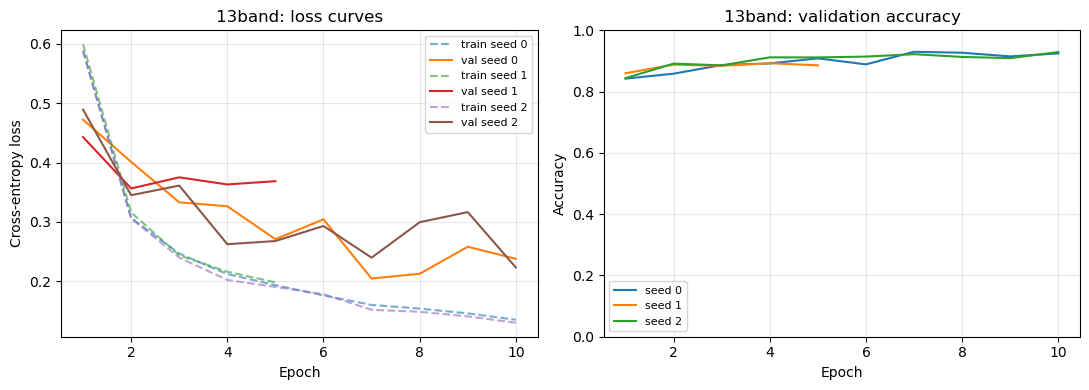

CNN metrics, by input and split (mean and std across seeds):


accuracy         macro_f1        
                 mean     std     mean     std
split input                                   
test  13band   0.9422  0.0140   0.9372  0.0161
      rgb      0.8759  0.0108   0.8571  0.0150
val   13band   0.9157  0.0239   0.9071  0.0246
      rgb      0.8578  0.0208   0.8413  0.0216


Per-class report: rgb, seed 0
                      precision    recall  f1-score   support

          AnnualCrop       0.86      0.95      0.90       367
              Forest       0.97      0.94      0.95       464
HerbaceousVegetation       0.56      0.79      0.65       266
             Highway       0.81      0.71      0.76       329
          Industrial       0.89      0.97      0.93       345
             Pasture       0.95      0.90      0.93       317
       PermanentCrop       0.82      0.47      0.60       293
         Residential       0.99      0.96      0.97       486
               River       0.79      0.78      0.78       233
             SeaLake       0.91      0.95      0.93       415

            accuracy                           0.86      3515
           macro avg       0.85      0.84      0.84      3515
        weighted avg       0.87      0.86      0.86      3515


Per-class report: 13band, seed 0
                      precision    recall  f1-score   support

 

In [5]:
import matplotlib.pyplot as plt

for input_type in ('rgb', '13band'):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for seed in SEEDS:
        run = cnn_history[(cnn_history['input'] == input_type) & (cnn_history['seed'] == seed)]
        axes[0].plot(run['epoch'], run['train_loss'], ls='--', alpha=.6, label=f'train seed {seed}')
        axes[0].plot(run['epoch'], run['val_loss'], label=f'val seed {seed}')
        axes[1].plot(run['epoch'], run['val_accuracy'], label=f'seed {seed}')
    axes[0].set(title=f'{input_type}: loss curves', xlabel='Epoch', ylabel='Cross-entropy loss')
    axes[1].set(title=f'{input_type}: validation accuracy', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1))
    for ax in axes:
        ax.grid(alpha=.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(figures_dir / f'cnn_{input_type}_training.png', dpi=150, bbox_inches='tight')
    plt.show()

print('CNN metrics, by input and split (mean and std across seeds):')
display(cnn_results.groupby(['split', 'input'])[['accuracy', 'macro_f1']].agg(['mean', 'std']).round(4))

for input_type in ('rgb', '13band'):
    pred = pd.read_csv(predictions_dir / f'cnn_{input_type}_seed0.csv')
    print(f'\nPer-class report: {input_type}, seed 0')
    print(classification_report(pred['y_true'], pred['y_pred'],
                                labels=label_ids, target_names=list(CLASS_NAMES), zero_division=0))

print('Saved metrics to:', results_dir / 'cnn_results.csv')
print('Saved predictions to:', predictions_dir)
print('Saved training curves to:', figures_dir)
